# Carbon-cycle impulse response model (Joos et al., 2013)

**Question:** How well can a carbon-cycle model reproduce the observed rise in atmospheric CO₂ using historical global CO₂ emissions?

This notebook:
1. Defines the Joos et al. (2013) CO₂ impulse response function (IRF).
2. **Validation:** simulates a 100 GtC pulse and checks the fraction left after 1,000 years against the published 25 ± 9%.
3. **Application:** runs historical emissions (1850–2024) through the IRF and compares predicted CO₂ with the Mauna Loa record.

**Data files (same folder as this notebook):**
- `global_emissions_1850_2024.csv`: global fossil and land-use-change CO₂ emissions in MtCO₂/yr. These are Global Carbon Budget numbers, taken from Our World in Data's `co2-data` repository.
- `mlo_annual.csv`: annual mean CO₂ at Mauna Loa in ppm. This copy is the NOAA record. The Scripps record from the same site agrees to within a few tenths of a ppm. To use Scripps instead, see the note in Section 3.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Multi-model-mean IRF fit from Joos et al. (2013); the same values are used in IPCC AR5 (Myhre et al., 2013)
a0, a1, a2, a3 = 0.2173, 0.2240, 0.2824, 0.2763   # fractions (sum = 1)
tau1, tau2, tau3 = 394.4, 36.54, 4.304            # e-folding times, years

GTC_PER_PPM = 2.124        # 1 ppm CO2 in the atmosphere = 2.124 GtC
GTC_PER_MTCO2 = 12/44/1000 # MtCO2 -> GtC

def irf(t):
    """Fraction of a CO2 pulse still in the atmosphere t years after emission."""
    t = np.asarray(t, dtype=float)
    return a0 + a1*np.exp(-t/tau1) + a2*np.exp(-t/tau2) + a3*np.exp(-t/tau3)

print("a0+a1+a2+a3 =", a0+a1+a2+a3)
for t in [0, 1, 20, 100, 500, 1000]:
    print(f"IRF({t:>4} yr) = {irf(t):.3f}")

a0+a1+a2+a3 = 1.0
IRF(   0 yr) = 1.000
IRF(   1 yr) = 0.935
IRF(  20 yr) = 0.596
IRF( 100 yr) = 0.409
IRF( 500 yr) = 0.280
IRF(1000 yr) = 0.235


## 1. Validation: a 100 GtC pulse

Joos et al. (2013) report that **25 ± 9%** of a 100 GtC pulse is still in the atmosphere after 1,000 years. That number is the mean and spread across the full models. The IRF is a fit to the mean of those models, so it should land close to 25%.

Remaining after 1000 yr: 23.5 GtC (23.5%)
Published: 25% +/- 9%  ->  range 16%-34%
PASS


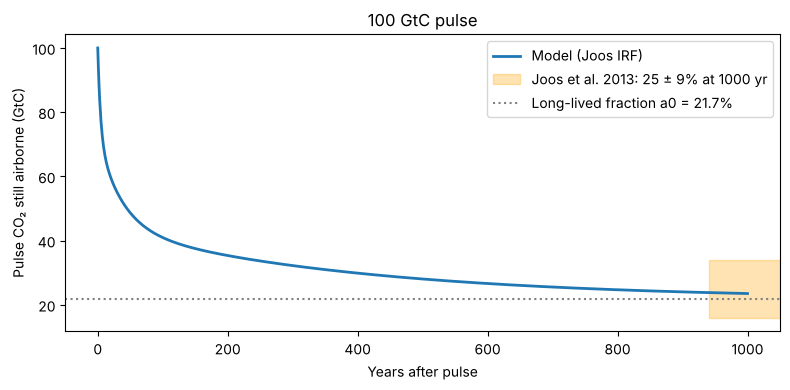

In [2]:
pulse = 100.0  # GtC
t = np.arange(0, 1001)
remaining = pulse * irf(t)

frac_1000 = irf(1000)
lo, hi = 0.25 - 0.09, 0.25 + 0.09
print(f"Remaining after 1000 yr: {remaining[-1]:.1f} GtC ({frac_1000:.1%})")
print(f"Published: 25% +/- 9%  ->  range {lo:.0%}-{hi:.0%}")
print("PASS" if lo <= frac_1000 <= hi else "FAIL")

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(t, remaining, lw=2, label="Model (Joos IRF)")
ax.axhspan(lo*100, hi*100, xmin=0.9, color="orange", alpha=0.3, label="Joos et al. 2013: 25 ± 9% at 1000 yr")
ax.axhline(a0*100, ls=":", c="gray", label=f"Long-lived fraction a0 = {a0:.1%}")
ax.set(xlabel="Years after pulse", ylabel="Pulse CO₂ still airborne (GtC)", title="100 GtC pulse")
ax.legend(); plt.tight_layout(); plt.show()

## 2. Historical emissions → predicted atmospheric CO₂

CO₂ in year *T* is the starting concentration plus whatever is left of every earlier year's emissions:

$$C(T) = C_0 + \frac{1}{2.124}\sum_{s \le T} E(s)\,\mathrm{IRF}(T - s + 0.5)$$

The +0.5 treats each year's emissions as released at mid-year. The model starts in 1850 with **C₀ = 285 ppm**, the 1850 value the Global Carbon Budget uses.

The model is run twice:
- **Fossil only** (fossil fuels + cement)
- **Fossil + land-use change** (adds deforestation and other land-use emissions). This is the total that actually entered the atmosphere.

In [3]:
em = pd.read_csv("data/global_emissions_1850_2024.csv")
em["fossil_GtC"] = em.fossil_MtCO2 * GTC_PER_MTCO2
em["luc_GtC"] = em.landuse_MtCO2 * GTC_PER_MTCO2
em["total_GtC"] = em.fossil_GtC + em.luc_GtC
years = em.year.values
print(f"Cumulative 1850-2024: fossil {em.fossil_GtC.sum():.0f} GtC, land use {em.luc_GtC.sum():.0f} GtC, total {em.total_GtC.sum():.0f} GtC")

def run_model(E, C0=285.0, scale=1.0):
    """Convolve annual emissions E (GtC/yr) with the IRF -> CO2 (ppm) at the end of each year."""
    E = np.asarray(E) * scale
    kernel = irf(np.arange(len(E)) + 0.5)
    airborne = np.convolve(E, kernel)[:len(E)]  # GtC still in the atmosphere
    return C0 + airborne / GTC_PER_PPM

em["C_fossil"] = run_model(em.fossil_GtC)
em["C_total"] = run_model(em.total_GtC)

Cumulative 1850-2024: fossil 503 GtC, land use 247 GtC, total 750 GtC


## 3. Compare with Mauna Loa

*To use the Scripps file instead:* download the monthly Mauna Loa CSV from scrippsco2.ucsd.edu. Average the monthly values for each year, then build a Series indexed by year with the same name, `obs`.

In [4]:
mlo = pd.read_csv("data/mlo_annual.csv")
obs = mlo.set_index("Year")["Mean"]

m = em.set_index("year")
common = obs.index.intersection(m.index)

def score(pred):
    r = pred[common] - obs[common]
    return dict(RMSE=np.sqrt((r**2).mean()), bias=r.mean(),
                pred_2024=pred[2024], obs_2024=obs[2024],
                rise_pred=pred[2024]-pred[1959], rise_obs=obs[2024]-obs[1959])

results = pd.DataFrame({"Fossil only": score(m.C_fossil), "Fossil + land use": score(m.C_total)}).T
print(results.round(1))

                   RMSE  bias  pred_2024  obs_2024  rise_pred  rise_obs
Fossil only         5.9  -5.5      422.4     424.6      114.6     108.6
Fossil + land use  41.7  40.9      477.8     424.6      134.6     108.6


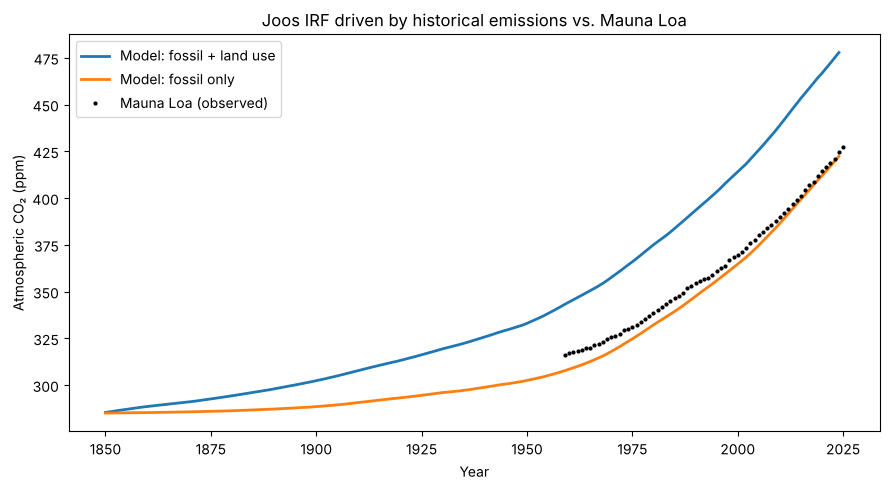

In [5]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(m.index, m.C_total, lw=2, label="Model: fossil + land use")
ax.plot(m.index, m.C_fossil, lw=2, label="Model: fossil only")
ax.plot(obs.index, obs.values, "k.", ms=4, label="Mauna Loa (observed)")
ax.set(xlabel="Year", ylabel="Atmospheric CO₂ (ppm)", title="Joos IRF driven by historical emissions vs. Mauna Loa")
ax.legend(); plt.tight_layout(); plt.show()

## 4. Why the full-emissions run overshoots: airborne fraction

The **airborne fraction** is the share of all emitted carbon that is still in the atmosphere. If the model overshoots, its airborne fraction is too high, which means its sinks are too weak.

In [6]:
obs_rise_GtC = (obs[2024] - 285.0) * GTC_PER_PPM
model_rise_GtC = (m.C_total[2024] - 285.0) * GTC_PER_PPM
cum = em.total_GtC.sum()
print(f"Observed atmospheric increase 1850-2024: {obs_rise_GtC:.0f} GtC -> airborne fraction {obs_rise_GtC/cum:.0%}")
print(f"Model (fossil + land use):                {model_rise_GtC:.0f} GtC -> airborne fraction {model_rise_GtC/cum:.0%}")

Observed atmospheric increase 1850-2024: 297 GtC -> airborne fraction 40%
Model (fossil + land use):                410 GtC -> airborne fraction 55%


**Interpretation (talking points for your write-up):**
- The **fossil-only** run tracks Mauna Loa within a few ppm, but it gets there for the wrong reason. It leaves out roughly a third of the carbon that was really emitted, and that missing carbon cancels out sinks in the model that are too weak.
- The **complete** run (fossil + land use) **overshoots by tens of ppm** by 2024. The Joos IRF comes from pulses added on top of a **constant 389 ppm background**. In that state the ocean is already more acidic and buffers less, so a pulse is removed more slowly than it would have been in the 1800s.
- The IRF also treats the carbon cycle as **linear**. It leaves out CO₂ fertilization, which makes the land sink grow as CO₂ rises. In reality the land and ocean together have taken up about half of all emissions.
- So the IRF does well at its intended job, the 100 GtC pulse check in Section 1, which is used for emission metrics. It has clear limits when used as a full historical carbon-cycle model. That contrast is a strong answer to Question 1.

## 5. Sensitivity: scale emissions or change the period

In [7]:
def scenario(scale=1.0, start=1850, use_luc=True):
    """Start in 1850 at 285 ppm, or in any year >= 1959 at the Mauna Loa value for that year."""
    E = (em.total_GtC if use_luc else em.fossil_GtC).where(em.year >= start, 0.0).values
    sel = em.year >= start
    C0 = 285.0 if start == 1850 else obs[start]
    # emissions before `start` are set to zero, so the run begins at C0 in year start-1
    pred = pd.Series(run_model(E[sel], C0=C0, scale=scale), index=years[sel])
    return pred

for s in [0.8, 1.0, 1.2]:
    p = scenario(scale=s)
    print(f"scale {s:.1f}: CO2 in 2024 = {p[2024]:.1f} ppm (obs {obs[2024]})")
p59 = scenario(start=1959)
print(f"Start in 1959 at {obs[1959]} ppm: CO2 in 2024 = {p59[2024]:.1f} ppm")
print("Note: a run that starts in 1959 ignores the carbon from pre-1959 emissions that sinks were still removing. It assumes that carbon stays put, which biases the result upward.")

scale 0.8: CO2 in 2024 = 439.3 ppm (obs 424.61)
scale 1.0: CO2 in 2024 = 477.8 ppm (obs 424.61)
scale 1.2: CO2 in 2024 = 516.4 ppm (obs 424.61)
Start in 1959 at 315.98 ppm: CO2 in 2024 = 467.7 ppm
Note: a run that starts in 1959 ignores the carbon from pre-1959 emissions that sinks were still removing. It assumes that carbon stays put, which biases the result upward.


## 6. Direct checks against the scientific model

These checks test the model's math directly against the IRF equation and the published numbers. None of them use Mauna Loa.

1. **Mass conservation at t = 0.** IRF(0) must be 1, since the whole pulse starts in the air. That requires a0 + a1 + a2 + a3 = 1.
2. **Hand calculation at 1,000 yr.** The 394-yr term is the only exponential still contributing, so IRF(1000) ≈ a0 + a1·e^(−1000/394.4).
3. **Second published number.** Joos et al. give AGWP₁₀₀ = 92.5 × 10⁻¹⁵ W m⁻² yr per kg CO₂. Divide by CO₂'s radiative efficiency, 1.76 × 10⁻¹⁵ W m⁻² per kg (the AR5 value of 1.37 × 10⁻⁵ W m⁻² per ppb, converted to per kg). The result, about 52.6 yr, is the time-integrated IRF over 100 years. The analytic integral is a0·100 + Σ aᵢτᵢ(1 − e^(−100/τᵢ)).
4. **Independent implementation.** Each IRF term is a box that receives aᵢ of each year's emissions and loses carbon at the rate 1/τᵢ (the a0 box never loses any). Stepping those four boxes year by year must give the same answer as the convolution.
5. **Analytic test case.** For constant emissions E, the airborne carbon after T years is E·[a0·T + Σ aᵢτᵢ(1 − e^(−T/τᵢ))].

In [8]:
a = np.array([a0, a1, a2, a3]); tau = np.array([tau1, tau2, tau3])
checks = []

# 1. mass conservation
checks.append(("IRF(0) = 1", irf(0), 1.0, abs(irf(0) - 1) < 1e-9))

# 2. hand calculation at 1000 yr
hand = a0 + a1*np.exp(-1000/tau1)
checks.append(("IRF(1000) by hand vs. code", hand, irf(1000), abs(hand - irf(1000)) < 1e-6))

# 3. integrated IRF over 100 yr vs. value implied by the published AGWP
I100 = a0*100 + (a[1:]*tau*(1 - np.exp(-100/tau))).sum()
implied = 92.5/1.76
checks.append(("∫IRF 0-100 yr (yr) vs. AGWP-implied", I100, implied, abs(I100 - implied)/implied < 0.02))

# 4. four-box model vs. convolution, using the real emissions history
E = em.total_GtC.values
R = np.zeros(4); box = []
for e in E:
    R = R*np.r_[1, np.exp(-1/tau)] + a*e*np.r_[1, np.exp(-0.5/tau)]  # added mid-year, then decays
    box.append(R.sum())
conv = np.convolve(E, irf(np.arange(len(E)) + 0.5))[:len(E)]
diff = np.abs(np.array(box) - conv).max()
checks.append(("Box model vs. convolution (max GtC diff)", diff, 0.0, diff < 1e-6))

# 5. constant emissions: analytic vs. numerical
T, Ec = 100, 10.0
analytic = Ec*(a0*T + (a[1:]*tau*(1 - np.exp(-T/tau))).sum())
numeric = np.convolve(np.full(T, Ec), irf(np.arange(T) + 0.5))[T-1]
checks.append(("10 GtC/yr for 100 yr: analytic vs. numeric (GtC)", analytic, numeric, abs(analytic - numeric)/analytic < 1e-3))

print(pd.DataFrame(checks, columns=["check", "model", "expected", "pass"]).round(4).to_string(index=False))

                                           check    model  expected  pass
                                      IRF(0) = 1   1.0000    1.0000  True
                      IRF(1000) by hand vs. code   0.2350    0.2350  True
             ∫IRF 0-100 yr (yr) vs. AGWP-implied  52.3554   52.5568  True
        Box model vs. convolution (max GtC diff)   0.0000    0.0000  True
10 GtC/yr for 100 yr: analytic vs. numeric (GtC) 523.5539  523.5241  True
